In [18]:

#from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
import joblib # for picking
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
from sklearn.model_selection import train_test_split
%matplotlib inline


In [20]:
df = pd.read_csv('data/diabetes2.csv')
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


In [21]:
df.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

In [22]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [24]:
#df['Outcome'].column_names = ['Outcome']
df['Outcome'].value_counts()

Outcome
0    500
1    268
Name: count, dtype: int64

In [29]:
X =df[['Pregnancies','Glucose','BloodPressure','SkinThickness','Insulin','BMI','DiabetesPedigreeFunction','Age']]
y = df['Outcome']

In [30]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3,random_state=42)

In [31]:
len(X_train)

537

In [27]:
X_train

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
334,1,95,60,18,58,23.9,0.260,22
139,5,105,72,29,325,36.9,0.159,28
485,0,135,68,42,250,42.3,0.365,24
547,4,131,68,21,166,33.1,0.160,28
18,1,103,30,38,83,43.3,0.183,33
...,...,...,...,...,...,...,...,...
71,5,139,64,35,140,28.6,0.411,26
106,1,96,122,0,0,22.4,0.207,27
270,10,101,86,37,0,45.6,1.136,38
435,0,141,0,0,0,42.4,0.205,29


In [35]:
len(X_test)

231

In [32]:
#defining  model , evaluating model and testing accuracy
modelLogReg = LogisticRegression()
modelLogReg.fit(X_train, y_train)
y_pred = modelLogReg.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.7402597402597403


C:\Ayesha\python\Machine-Learning\Ayesha-Practice\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [34]:

print(confusion_matrix(y_test,y_pred))

[[121  30]
 [ 30  50]]


In [36]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.80      0.80      0.80       151
           1       0.62      0.62      0.62        80

    accuracy                           0.74       231
   macro avg       0.71      0.71      0.71       231
weighted avg       0.74      0.74      0.74       231



In [ ]:
#calculate teh metrics manuall

In [48]:
feature_importance_modelLogReg = pd.DataFrame({
    "Feature" : X_train.columns,
    "Coefficient" : modelLogReg.coef_[0],
    "Absolute_Importance" : np.abs(modelLogReg.coef_[0])
}).sort_values(by = "Absolute_Importance", ascending = False)
    
feature_importance_modelLogReg

,Feature,Coefficient,Absolute_Importance
6,DiabetesPedigreeFunction,0.523938,0.523938
5,BMI,0.107612,0.107612
0,Pregnancies,0.056544,0.056544
7,Age,0.035826,0.035826
1,Glucose,0.035585,0.035585
2,BloodPressure,-0.010878,0.010878
3,SkinThickness,-0.001791,0.001791
4,Insulin,-0.000989,0.000989


In [51]:
import matplotlib.pyplot as plt

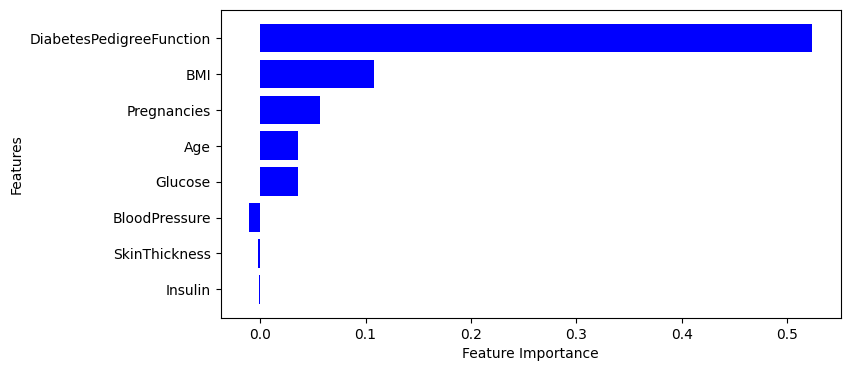

In [55]:
plt.figure(figsize=(8,4))
plt.barh(feature_importance_modelLogReg['Feature'],feature_importance_modelLogReg['Coefficient'] ,color='b')
plt.xlabel('Feature Importance')
plt.ylabel('Features')
plt.gca().invert_yaxis()
plt.show()

In [39]:
from sklearn.tree import DecisionTreeClassifier # classification task

In [40]:
modeldescisionTreeClassifer = DecisionTreeClassifier()
modeldescisionTreeClassifer

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [41]:
modeldescisionTreeClassifer.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [42]:
y_pred_decition_tree =modeldescisionTreeClassifer.predict(X_test)

In [43]:
accuray_decision_tree = accuracy_score(y_test,y_pred_decition_tree)
accuray_decision_tree

0.7142857142857143

In [44]:
print(classification_report(y_test,y_pred_decition_tree))

              precision    recall  f1-score   support

           0       0.83      0.70      0.76       151
           1       0.57      0.74      0.64        80

    accuracy                           0.71       231
   macro avg       0.70      0.72      0.70       231
weighted avg       0.74      0.71      0.72       231



In [45]:
print(confusion_matrix(y_test,y_pred_decition_tree))

[[106  45]
 [ 21  59]]


In [47]:
feature_importance = pd.DataFrame({
    "Feature" : X_train.columns,
    "Coefficient" : modeldescisionTreeClassifer.coef_[0],
    "Absolute_Importance" : np.abs(modeldescisionTreeClassifer.coef_[0])
}).sort_values(by = "Absolute_Importance", ascending = False)
    
feature_importance

AttributeError: 'DecisionTreeClassifier' object has no attribute 'coef_'

In [60]:
from sklearn.ensemble import RandomForestClassifier


In [62]:
model_random_forest = RandomForestClassifier(n_estimators=100)
model_random_forest.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [63]:
y_pred =model_random_forest.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.81      0.79      0.80       151
           1       0.62      0.64      0.63        80

    accuracy                           0.74       231
   macro avg       0.71      0.72      0.71       231
weighted avg       0.74      0.74      0.74       231



In [64]:
joblib.dump(model_random_forest, filename='RandomForestdiabetes_model.pkl')
print('Diabetes Model Saved.')

Diabetes Model Saved.


In [ ]:
#Accuracy in ML how good the model is generalizing.
#imabalace data set resujlts in overfitting.
#model is not generalizing well underfillting.